# 02 - Reviewing the submission
Checks the committed submission files and shows what the router decided.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sub = Path("..") / ".." / "submission"
pred = pd.read_csv(sub / "R2_predictions.csv")
top5 = pd.read_csv(sub / "R2_size_chart_top5.csv")
pred["decision"].value_counts()

decision
auto_approve    15826
inspect           927
escalate          179
Name: count, dtype: int64

In [2]:
assert pred["return_id"].is_unique and pred["confidence"].between(0, 1).all()
len(pred)

16932

## Confidence (P(abusive)) by decision

In [3]:
pred.groupby("decision")["confidence"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
decision,,,,,,,,
auto_approve,15826.0,0.027,0.053,0.001,0.003,0.013,0.021,0.375
escalate,179.0,0.986,0.007,0.982,0.982,0.982,0.982,0.999
inspect,927.0,0.764,0.150,0.516,0.590,0.718,0.914,0.950


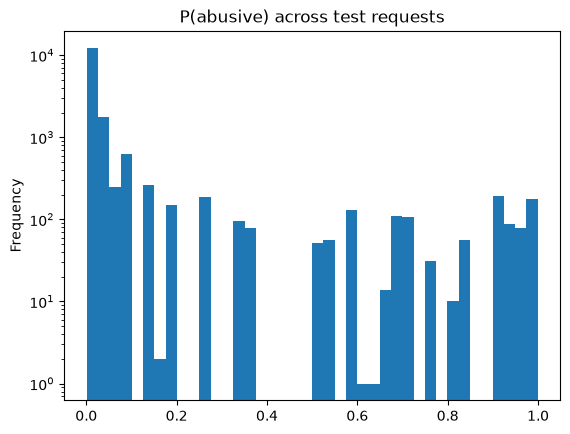

In [4]:
pred["confidence"].plot.hist(bins=40, log=True, title="P(abusive) across test requests")
plt.show()

## Example justifications

In [5]:
for decision in ["escalate", "inspect", "auto_approve"]:
    print(decision)
    for text in pred[pred["decision"] == decision]["justification"].head(3):
        print("  -", text)

escalate
  - Escalate (P(abusive)=98%): 21 earlier return(s) already judged abusive; reason text repeats the customer's earlier returns; returned 18 days after delivery.
  - Escalate (P(abusive)=98%): 8 earlier return(s) already judged abusive; reason text repeats the customer's earlier returns; returned 17 days after delivery.
  - Escalate (P(abusive)=98%): 4 earlier return(s) already judged abusive; reason text repeats the customer's earlier returns; 58% of past orders returned.
inspect
  - Inspect (P(abusive)=90%): 3 earlier return(s) already judged abusive; reason text repeats the customer's earlier returns; returned 17 days after delivery. Cheap check, not a rejection.
  - Inspect (P(abusive)=59%): 5 earlier return(s) already judged abusive; high-value item (Rs 5269); single-item order. Cheap check, not a rejection.
  - Inspect (P(abusive)=53%): 1 earlier return(s) already judged abusive; returned 11 days after delivery; cash-on-delivery order. Cheap check, not a rejection.
auto_a

## Size-chart top 5

In [6]:
top5

,rank,product_id
0,1,PRD-YIME3XJ6
1,2,PRD-6JG12RLX
2,3,PRD-OSNR3LA5
3,4,PRD-7NDH0OJO
4,5,PRD-THXMYY0T
